# Stage 06 — space-to-space results against their closed forms

Rounds 29 to 31 rendered three space-to-space scenario families (`manifold_run_specs/s2s/`, written by `scripts/s2s_scenarios.py`) and round 32 recorded one result per run in `docs/data/s2s_results.jsonl` (`scripts/s2s_measure.py`). `tests/test_s2s_results.py` asserts the closed-form cases against those records. This notebook reads the same records and reproduces those checks, one plot per case against its model, with each residual printed beside the tolerance the test uses:

1. **Resolved plate, flux against range.** A 20 m Lambertian plate at 12.5 to 100 km: the integrated signal in full pixels against the plate's footprint in pixels, and the footprint times range squared.
2. **Exposure.** 1 and 20 ms against 5 ms: the image sum scales with the exposure.
3. **Sun zenith.** Solar zenith 30 and 60 degrees against 0: the plate's signal scales as cos θs; the barred background of family III likewise.
4. **Sphere phase function.** A hyperresolved 10 m Lambertian sphere from 0 to 150 degrees of phase against Φ(a) = (sin a + (π − a) cos a) / π.
5. **Unresolved plate against the R⁻² line.** A 0.5 m plate at 12.5 to 800 km, with and without the `::IMPORTANT::` label, and its sub-pixel breakdown (the platform moved by 0 to 0.75 of a pixel). The test asserts no unresolved case; the residuals are printed without a tolerance.
6. **Coverage points (round 38).** The cells `docs/s2s_coverage.md` found empty that have a closed form, at a 64 x 64 window: a flat plate under cos(look) cos(zenith), the 0.5 m plate at 25 km under the Sun, and family II's plates and background moving together (flux, and the fitted sweep without a tolerance).
7. **The streak shortfall (round 39).** The controls that separate the resolved streak's 2 % shortfall: the generator's temporal sample count, the object's width, and (quoted from scratch renders) DIRSIG's per-pixel path count.

Nothing is rendered: the notebook needs no DIRSIG, no network and no GPU, and runs in a few seconds. It ends with what the SDK cannot express for this geometry (`docs/Space_to_space_characterization.md`).

---
# Setup

The records are read as JSON lines. The tolerances are read from `tests/test_s2s_results.py` (its `TOL_*` constants, parsed, not imported), so the residuals here are measured against the same numbers the suite uses.

In [1]:
import ast
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = PROJECT / "docs" / "data" / "s2s_results.jsonl"
TEST = PROJECT / "tests" / "test_s2s_results.py"

records = {r["spec"]: r for r in (json.loads(line) for line in RESULTS.read_text().splitlines() if line.strip())}
TOL = {node.targets[0].id: ast.literal_eval(node.value) for node in ast.parse(TEST.read_text()).body
       if isinstance(node, ast.Assign) and len(node.targets) == 1 and getattr(node.targets[0], "id", "").startswith("TOL_")}
print(f"{len(records)} records from {RESULTS.relative_to(PROJECT)}; families", sorted({r['family'] for r in records.values()}))
print("tolerances:", ", ".join(f"{k} {v:g}" for k, v in TOL.items()))


def total(name):
    """The image sum in e-/m^2: the flux closure's equivalent pixels times the full-pixel signal."""
    r = records[name]
    return r["measured"] * r["full_pixel"]


def report(rows, tol_name):
    """Print each residual |measured / closed form - 1| beside the test's tolerance; return the largest."""
    tol = TOL.get(tol_name)
    for label, residual in rows:
        verdict = "" if tol is None else ("within" if residual <= tol else "OUTSIDE")
        print(f"  {label:44s} residual {residual:.3e}" + ("" if tol is None else f"   tolerance {tol:.3g}  {verdict}"))
    worst = max(r for _, r in rows)
    print(f"  largest {worst:.3e}" + ("" if tol is None else f" against {tol_name} = {tol:g}"))
    return worst


HYP = "s2s-hyperresolved-r{r}km-v0mps-e{e}ms-l{l}-z{z}-d0"
KM = {"12p5": 12.5, "25": 25.0, "50": 50.0, "100": 100.0, "200": 200.0, "400": 400.0, "800": 800.0}
worst = {}

103 records from docs/data/s2s_results.jsonl; families [1, 2, 3]
tolerances: TOL_FLUX_PLATE 0.00816, TOL_R2 0.00721, TOL_EXPOSURE 1.34e-15, TOL_LOOK 0.000803, TOL_LOOK_BACKGROUND 0.000822, TOL_SUN 4.54e-05, TOL_PHASE 0.00982, TOL_PERIOD 0.00362, TOL_BAR 0.000154, TOL_WINDOW 0.000134, TOL_PLATE_LOOK_SUN 0.000987, TOL_SMALL_SUN 0.000819, TOL_FLUX_BOTH 0.00162, TOL_FLUX_STREAK_100KM 0.00893, TOL_SHORTFALL_WIDTH 0.00038


---
# 1 — Resolved plate: flux against range

Each record's `measured` is the image sum over the full-pixel signal (equivalent pixels) and `expected` the plate's projected area over the pixel footprint squared, A cos θv / (R p / f)². Flux closure is their ratio; the footprint times R² is the same at every range, against 25 km. The edge pixels' sampling scatter grows as the plate covers fewer pixels (round 30 measured it across seeds).

flux closure (TOL_FLUX_PLATE):
   12.5 km    2396.89 /   2397.08 px           residual 7.984e-05   tolerance 0.00816  within
   25.0 km     599.84 /    599.27 px           residual 9.506e-04   tolerance 0.00816  within
   50.0 km     150.62 /    149.82 px           residual 5.356e-03   tolerance 0.00816  within
  100.0 km      37.76 /     37.45 px           residual 8.159e-03   tolerance 0.00816  within
  largest 8.159e-03 against TOL_FLUX_PLATE = 0.00816
footprint x range^2 against 25 km (TOL_R2):
   12.5 km                                     residual 1.029e-03   tolerance 0.00721  within
   50.0 km                                     residual 4.401e-03   tolerance 0.00721  within
  100.0 km                                     residual 7.202e-03   tolerance 0.00721  within
  largest 7.202e-03 against TOL_R2 = 0.00721


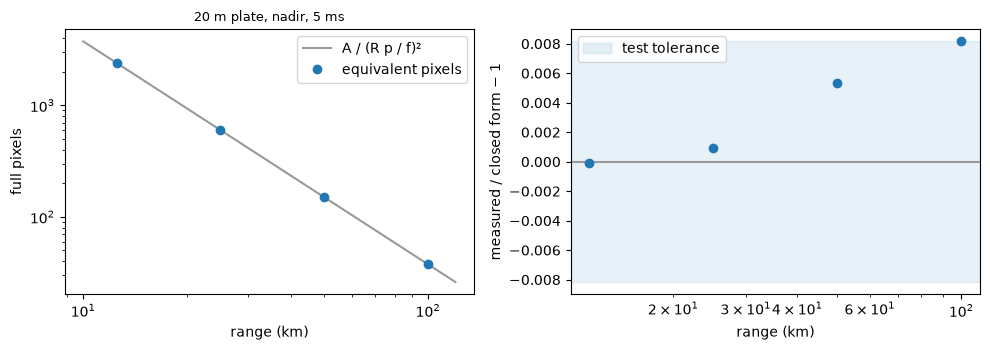

In [2]:
ranges = ["12p5", "25", "50", "100"]
plate = [records[HYP.format(r=r, e=5, l=0, z=0)] for r in ranges]
km = np.array([KM[r] for r in ranges])
got, want = np.array([p["measured"] for p in plate]), np.array([p["expected"] for p in plate])

print("flux closure (TOL_FLUX_PLATE):")
worst["flux closure"] = report([(f"{k:5.1f} km  {g:9.2f} / {w:9.2f} px", abs(g / w - 1)) for k, g, w in zip(km, got, want)],
                               "TOL_FLUX_PLATE")
print("footprint x range^2 against 25 km (TOL_R2):")
ref = got[1] * 25.0 ** 2
worst["R^2 footprint"] = report([(f"{k:5.1f} km", abs(g * k ** 2 / ref - 1)) for k, g in zip(km, got) if k != 25.0], "TOL_R2")

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6))
line = np.geomspace(10, 120, 50)
a.loglog(line, want[1] * (25.0 / line) ** 2, "-", color="0.6", label="A / (R p / f)²")
a.loglog(km, got, "o", label="equivalent pixels")
a.set_xlabel("range (km)"); a.set_ylabel("full pixels"); a.legend(); a.set_title("20 m plate, nadir, 5 ms", fontsize=9)
b.axhline(0, color="0.6")
b.plot(km, got / want - 1, "o")
b.axhspan(-TOL["TOL_FLUX_PLATE"], TOL["TOL_FLUX_PLATE"], color="C0", alpha=0.1, label="test tolerance")
b.set_xscale("log"); b.set_xlabel("range (km)"); b.set_ylabel("measured / closed form − 1"); b.legend()
plt.tight_layout()

---
# 2 — Exposure

The 25 km plate at 1, 5 and 20 ms. The image sum at e ms over the sum at 5 ms is e / 5: the same samples scaled, so the residual is at double precision.

exposure scaling (TOL_EXPOSURE):
   1 ms / 5 ms = 0.200000000000000             residual 1.332e-15   tolerance 1.34e-15  within
  20 ms / 5 ms = 4.000000000000000             residual 0.000e+00   tolerance 1.34e-15  within
  largest 1.332e-15 against TOL_EXPOSURE = 1.34e-15


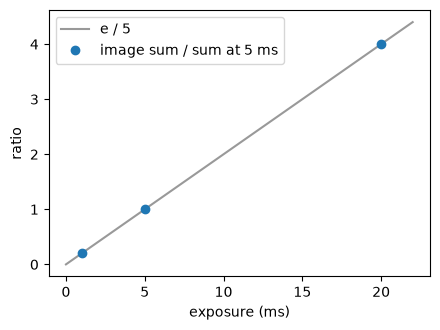

In [3]:
exp = [1, 5, 20]
sums = np.array([total(HYP.format(r=25, e=e, l=0, z=0)) for e in exp])
print("exposure scaling (TOL_EXPOSURE):")
worst["exposure"] = report([(f"{e:2d} ms / 5 ms = {s / sums[1]:.15f}", abs(s / sums[1] / (e / 5) - 1))
                            for e, s in zip(exp, sums) if e != 5], "TOL_EXPOSURE")
fig, ax = plt.subplots(figsize=(4.5, 3.4))
ax.plot([0, 22], [0, 22 / 5], "-", color="0.6", label="e / 5")
ax.plot(exp, sums / sums[1], "o", label="image sum / sum at 5 ms")
ax.set_xlabel("exposure (ms)"); ax.set_ylabel("ratio"); ax.legend()
plt.tight_layout()

---
# 3 — Sun zenith

The plate faces the zenith, so its radiance scales as cos θs (family I, θs 0, 30, 60 degrees). Family III's barred background, at 0 to 75 degrees, follows the same law (its `bar_level` measurement). The look-angle cases of the test (projected area, cos θv, families I and II) and family II's bar period are checked here too.

Sun zenith, plate (TOL_SUN):
  zenith 30: ratio 0.866036 vs cos 0.866025    residual 1.235e-05   tolerance 4.54e-05  within
  zenith 60: ratio 0.500023 vs cos 0.500000    residual 4.540e-05   tolerance 4.54e-05  within
  largest 4.540e-05 against TOL_SUN = 4.54e-05
Sun zenith, barred background (TOL_BAR):
  zenith  0: 0.50000 vs 0.50000                residual 8.753e-08   tolerance 0.000154  within
  zenith 30: 0.43302 vs 0.43301                residual 1.237e-05   tolerance 0.000154  within
  zenith 60: 0.25002 vs 0.25000                residual 6.389e-05   tolerance 0.000154  within
  zenith 75: 0.12943 vs 0.12941                residual 1.534e-04   tolerance 0.000154  within
  largest 1.534e-04 against TOL_BAR = 0.000154
look angle, family I (TOL_LOOK):
  look 30                                      residual 8.021e-04   tolerance 0.000803  within
  look 60                                      residual 4.334e-04   tolerance 0.000803  within
  largest 8.021e-04 against TOL_LOOK = 0.00

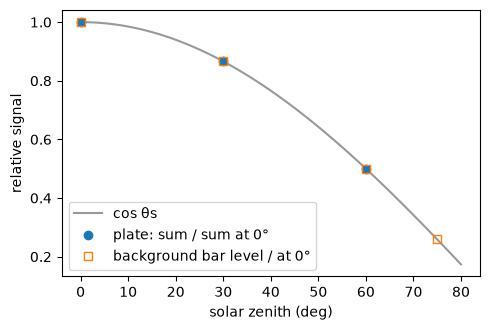

In [4]:
zen = [0, 30, 60]
sun = np.array([total(HYP.format(r=25, e=5, l=0, z=z)) for z in zen]) / total(HYP.format(r=25, e=5, l=0, z=0))
print("Sun zenith, plate (TOL_SUN):")
worst["sun zenith"] = report([(f"zenith {z:2d}: ratio {s:.6f} vs cos {math.cos(math.radians(z)):.6f}",
                               abs(s / math.cos(math.radians(z)) - 1)) for z, s in zip(zen, sun) if z], "TOL_SUN")

bars = {z: next(x for x in records[f"s2s3-background-z{z}"]["also"] if x["method"] == "bar_level") for z in (0, 30, 60, 75)}
print("Sun zenith, barred background (TOL_BAR):")
worst["bar level"] = report([(f"zenith {z:2d}: {b['measured']:.5f} vs {b['expected']:.5f}", abs(b["ratio"] - 1))
                             for z, b in bars.items()], "TOL_BAR")

print("look angle, family I (TOL_LOOK):")
worst["look I"] = report([(f"look {l}", abs(total(HYP.format(r=25, e=5, l=l, z=0)) / total(HYP.format(r=25, e=5, l=0, z=0))
                                            / math.cos(math.radians(l)) - 1)) for l in (30, 60)], "TOL_LOOK")
print("look angle against a background, family II (TOL_LOOK_BACKGROUND):")
worst["look II"] = report([(f"look {l}", abs(total(f"s2s2-look-l{l}") / total("s2s2-look-l0") / math.cos(math.radians(l)) - 1))
                           for l in (15, 30, 45, 60)], "TOL_LOOK_BACKGROUND")
print("background bar period, family II (TOL_PERIOD):")
worst["bar period"] = report([(f"look {l}", abs(next(x for x in records[f"s2s2-look-l{l}"]["also"]
                                                    if x["method"] == "background_period")["ratio"] - 1))
                              for l in (0, 15, 30, 45, 60)], "TOL_PERIOD")

fig, ax = plt.subplots(figsize=(5, 3.4))
t = np.linspace(0, 80, 100)
ax.plot(t, np.cos(np.radians(t)), "-", color="0.6", label="cos θs")
ax.plot(zen, sun, "o", label="plate: sum / sum at 0°")
ax.plot(list(bars), [b["measured"] / bars[0]["measured"] for b in bars.values()], "s", mfc="none", label="background bar level / at 0°")
ax.set_xlabel("solar zenith (deg)"); ax.set_ylabel("relative signal"); ax.legend()
plt.tight_layout()

---
# 4 — Sphere phase function

Family III's 10 m sphere at 25 km. For a Lambertian sphere the integrated signal is (2/3) π R² / g² × Φ(a) full pixels, g the pixel footprint. The phase angle a is the look angle plus the solar zenith; the sweep splits it equally, and three more records put 60 degrees all in the Sun, half and half, or all in the look. The unresolved 0.25 m labelled sphere is shown for comparison; the test asserts only the hyperresolved one.

hyperresolved sphere (TOL_PHASE):
  a0-l0-z0            314.140 /  313.777 px    residual 1.157e-03   tolerance 0.00982  within
  a20-l10-z10         296.611 /  296.253 px    residual 1.209e-03   tolerance 0.00982  within
  a40-l20-z20         251.618 /  251.153 px    residual 1.853e-03   tolerance 0.00982  within
  a60-l0-z60          191.427 /  191.090 px    residual 1.764e-03   tolerance 0.00982  within
  a60-l30-z30         191.400 /  191.090 px    residual 1.626e-03   tolerance 0.00982  within
  a60-l60-z0          191.382 /  191.090 px    residual 1.531e-03   tolerance 0.00982  within
  a80-l40-z40         128.841 /  128.631 px    residual 1.631e-03   tolerance 0.00982  within
  a100-l50-z50         74.375 /   74.145 px    residual 3.108e-03   tolerance 0.00982  within
  a120-l60-z60         34.275 /   34.201 px    residual 2.173e-03   tolerance 0.00982  within
  a135-l67p5-z67p5     15.287 /   15.156 px    residual 8.657e-03   tolerance 0.00982  within
  a150-l75-z75          4.

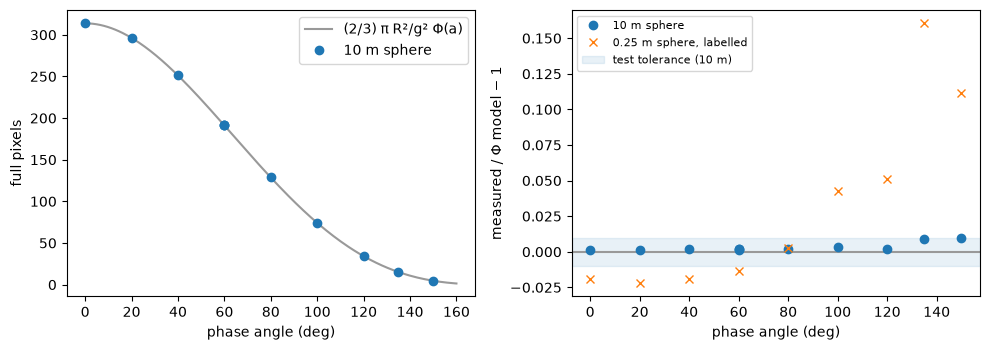

In [5]:
def phi(a):
    a = np.radians(a)
    return (np.sin(a) + (np.pi - a) * np.cos(a)) / np.pi

hyp = sorted(((int(n.split("-a")[1].split("-")[0]), n) for n in records if n.startswith("s2s3-phase-hyperresolved-")))
print("hyperresolved sphere (TOL_PHASE):")
worst["phase"] = report([(f"{n.removeprefix('s2s3-phase-hyperresolved-'):18s} {records[n]['measured']:8.3f} / "
                          f"{records[n]['expected']:8.3f} px", abs(records[n]["ratio"] - 1)) for _, n in hyp], "TOL_PHASE")
unr = sorted(((int(n.split("-a")[1].split("-")[0]), n) for n in records if n.startswith("s2s3-phase-unresolved-")))
print("unresolved labelled sphere (no test tolerance):")
report([(n.removeprefix("s2s3-phase-unresolved-"), abs(records[n]["ratio"] - 1)) for _, n in unr], None)

full = records[hyp[0][1]]["expected"] / phi(0)
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6))
grid = np.linspace(0, 160, 200)
a.plot(grid, full * phi(grid), "-", color="0.6", label="(2/3) π R²/g² Φ(a)")
a.plot([x for x, _ in hyp], [records[n]["measured"] for _, n in hyp], "o", label="10 m sphere")
a.set_xlabel("phase angle (deg)"); a.set_ylabel("full pixels"); a.legend()
b.axhline(0, color="0.6")
b.plot([x for x, _ in hyp], [records[n]["ratio"] - 1 for _, n in hyp], "o", label="10 m sphere")
b.plot([x for x, _ in unr], [records[n]["ratio"] - 1 for _, n in unr], "x", label="0.25 m sphere, labelled")
b.axhspan(-TOL["TOL_PHASE"], TOL["TOL_PHASE"], color="C0", alpha=0.1, label="test tolerance (10 m)")
b.set_xlabel("phase angle (deg)"); b.set_ylabel("measured / Φ model − 1"); b.legend(fontsize=8)
plt.tight_layout()

---
# 5 — Unresolved plate against the R⁻² line

The 0.5 m plate (the `::IMPORTANT::` labelled one and the same plate without the label), nadir, Sun at the zenith, 5 ms, with a black backstop behind it. Its expected signal is the R⁻² law at fixed area. Where the plate covers less than about a third of a pixel the signal rests on a few hypersampled hits, and the unlabelled plate is lost (`docs/Space_to_space_characterization.md`, E2). The sub-pixel breakdown moves the platform by 0, 0.25, 0.5 and 0.75 of a pixel footprint along both scene axes.

range km  expected px  labelled px   ratio  unlabelled px   ratio
    12.5     1.498176     1.489882   0.994       1.600000   1.068
    25.0     0.374544     0.372500   0.995       0.400000   1.068
    50.0     0.093636     0.076500   0.817       0.030000   0.320
   100.0     0.023409     0.016500   0.705       0.000000   0.000
   200.0     0.005852     0.004500   0.769       0.000000   0.000
   400.0     0.001463     0.000500   0.342       0.000000   0.000
   800.0     0.000366     0.000500   1.367       0.000000   0.000
labelled residuals (no test tolerance):
   12.5 km                                     residual 5.536e-03
   25.0 km                                     residual 5.457e-03
   50.0 km                                     residual 1.830e-01
  100.0 km                                     residual 2.951e-01
  200.0 km                                     residual 2.311e-01
  400.0 km                                     residual 6.583e-01
  800.0 km                          

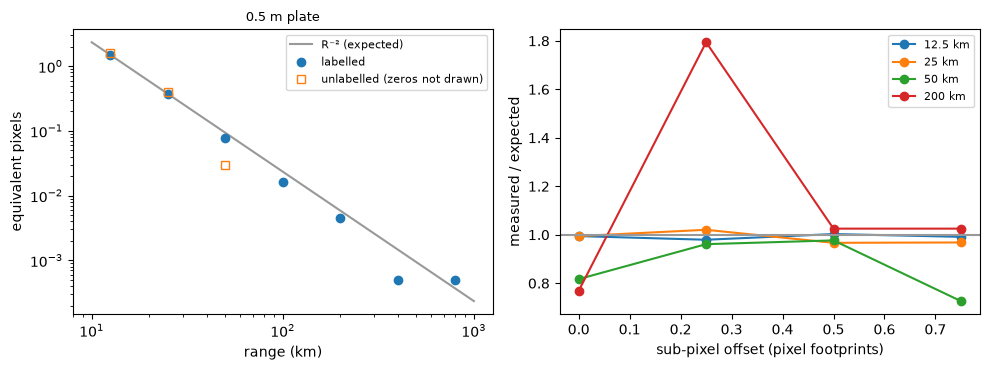

In [6]:
order = ["12p5", "25", "50", "100", "200", "400", "800"]
lab = {r: records[f"s2s-unresolved-r{r}km-v0mps-e5ms-l0-z0-d0"] for r in order}
plain = {r: records[f"s2s-unresolvedplain-r{r}km-v0mps-e5ms-l0-z0-d0"] for r in order}
print(f"{'range km':>8s} {'expected px':>12s} {'labelled px':>12s} {'ratio':>7s} {'unlabelled px':>14s} {'ratio':>7s}")
for r in order:
    print(f"{KM[r]:8.1f} {lab[r]['expected']:12.6f} {lab[r]['measured']:12.6f} {lab[r]['ratio']:7.3f} "
          f"{plain[r]['measured']:14.6f} {plain[r]['ratio']:7.3f}")
print("labelled residuals (no test tolerance):")
report([(f"{KM[r]:5.1f} km", abs(lab[r]["ratio"] - 1)) for r in order], None)

offsets = ["0", "0p25", "0p5", "0p75"]
sub = {r: [records[f"s2s-unresolved-r{r}km-v0mps-e5ms-l0-z0-d{o}"]["ratio"] for o in offsets] for r in ("12p5", "25", "50", "200")}
print("\nsub-pixel breakdown: ratio at offsets 0, 0.25, 0.5, 0.75 px")
for r, v in sub.items():
    print(f"  {KM[r]:5.1f} km  " + "  ".join(f"{x:.3f}" for x in v) + f"   spread {max(v) / min(v):.2f}x")

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.8))
km = np.array([KM[r] for r in order])
line = np.geomspace(10, 1000, 50)
a.loglog(line, lab["25"]["expected"] * (25.0 / line) ** 2, "-", color="0.6", label="R⁻² (expected)")
a.loglog(km, [lab[r]["measured"] for r in order], "o", label="labelled")
nz = [r for r in order if plain[r]["measured"] > 0]
a.loglog([KM[r] for r in nz], [plain[r]["measured"] for r in nz], "s", mfc="none", label="unlabelled (zeros not drawn)")
a.set_xlabel("range (km)"); a.set_ylabel("equivalent pixels"); a.legend(fontsize=8); a.set_title("0.5 m plate", fontsize=9)
for r, v in sub.items():
    b.plot([0, 0.25, 0.5, 0.75], v, "o-", label=f"{KM[r]:g} km")
b.axhline(1, color="0.6")
b.set_xlabel("sub-pixel offset (pixel footprints)"); b.set_ylabel("measured / expected"); b.legend(fontsize=8)
plt.tight_layout()

---
# 6 — Coverage points (round 38)

`docs/s2s_coverage.md` maps the records against the realism axes and lists the empty cells. Round 38 rendered twelve points for cells with a closed form, at a 64 x 64 window (the `-w64` specs; each ratio below is taken against the same window's baseline, the first point of each class). The resolved plate's baseline in the small window holds the native record's flux. A flat Lambertian plate seen `look` degrees off its normal with the Sun `z` degrees off it gives cos(look) cos(z), with the Sun on the far side (phase look + z). The labelled 0.5 m plate at 25 km (0.61 px) follows the Sun's cosine; its 60 degree look alone reads 0.922 of cos 60, a finding the test does not assert. Family II's `both` group (plates at 2000 m/s, the background at 1000 m/s) conserves the resolved plate's flux; its fitted sweep is printed beside speed × exposure over the footprint, without a tolerance (the fit has no optics).

In [7]:
W64 = "s2s-{c}-r25km-v0mps-e5ms-l{l}-z{z}-d0-w64"
cos = lambda d: math.cos(math.radians(d))

print("64 x 64 window against the native record, 20 m plate (TOL_WINDOW):")
worst["window"] = report([("sum w64 / sum native", abs(total(W64.format(c="hyperresolved", l=0, z=0))
                                                       / total(HYP.format(r=25, e=5, l=0, z=0)) - 1))], "TOL_WINDOW")
print("flat plate, cos(look) cos(zenith) (TOL_PLATE_LOOK_SUN):")
worst["plate look+sun"] = report([(f"look {l:2d}, zenith {z:2d}", abs(total(W64.format(c="hyperresolved", l=l, z=z))
                                   / total(W64.format(c="hyperresolved", l=0, z=0)) / (cos(l) * cos(z)) - 1))
                                  for l, z in ((30, 30), (45, 45), (60, 60), (0, 75))], "TOL_PLATE_LOOK_SUN")
print("0.5 m plate at 25 km, the Sun (TOL_SMALL_SUN):")
worst["small sun"] = report([(f"look {l:2d}, zenith {z:2d}", abs(total(W64.format(c="unresolved", l=l, z=z))
                              / total(W64.format(c="unresolved", l=0, z=0)) / (cos(l) * cos(z)) - 1))
                             for l, z in ((0, 60), (30, 30))], "TOL_SMALL_SUN")
small_look = total(W64.format(c="unresolved", l=60, z=0)) / total(W64.format(c="unresolved", l=0, z=0)) / cos(60)
print(f"  look 60 alone (not asserted): {small_look:.4f} of cos 60")
print("both group, flux closure (TOL_FLUX_BOTH):")
worst["both flux"] = report([(f"{e} ms", abs(records[f"s2s2-blur-both-e{e}ms-w64"]["ratio"] - 1))
                             for e in ("0p1", "1", "5")], "TOL_FLUX_BOTH")
print("both group, fitted sweep (px) against speed x exposure / footprint:")
for e in ("0p1", "1", "5"):
    s = next(x for x in records[f"s2s2-blur-both-e{e}ms-w64"]["also"] if x["method"] == "streak_length")
    print(f"  {e:>3s} ms  {s['measured']:7.3f} vs {s['expected']:7.3f}  ratio {s['ratio']:.4f}")

64 x 64 window against the native record, 20 m plate (TOL_WINDOW):
  sum w64 / sum native                         residual 1.334e-04   tolerance 0.000134  within
  largest 1.334e-04 against TOL_WINDOW = 0.000134
flat plate, cos(look) cos(zenith) (TOL_PLATE_LOOK_SUN):
  look 30, zenith 30                           residual 5.025e-04   tolerance 0.000987  within
  look 45, zenith 45                           residual 6.640e-04   tolerance 0.000987  within
  look 60, zenith 60                           residual 9.865e-04   tolerance 0.000987  within
  look  0, zenith 75                           residual 1.021e-04   tolerance 0.000987  within
  largest 9.865e-04 against TOL_PLATE_LOOK_SUN = 0.000987
0.5 m plate at 25 km, the Sun (TOL_SMALL_SUN):
  look  0, zenith 60                           residual 6.392e-05   tolerance 0.000819  within
  look 30, zenith 30                           residual 8.183e-04   tolerance 0.000819  within
  largest 8.183e-04 against TOL_SMALL_SUN = 0.000819
  lo

---
# 7 — The streak shortfall (round 39)

A resolved plate's fitted sweep reads about 2 % short of speed × exposure over the footprint at 5 and 20 ms (round 30, and round 38's `both` group). Round 39 separated three hypotheses, one factor at a time. **(1) The temporal sample count.** The generator's count (`integration_samples` 2 instead of 10) renders the same bytes, so DIRSIG5 does not use it (its manual: ray times are spread uniformly over the exposure). DIRSIG's own count is the paths per pixel. Scratch renders of the `both` 5 ms point at a fixed count (a focal-plane `<convergence>`, not a run-spec member) read 0.9988 of the sweep at 1000 paths, and 0.9874 and 0.9923 at 20 paths (seeds 1 and 2), against 0.9809 at the default adaptive count. The 100 km point below reads 0.9983 at 1000 paths. A sweep sampled at n instants would read (n − 1)/n, 0.95 at 20 paths, which is not what 20 paths gives. **(2) The measurement.** Re-measured with other definitions of the length (the fit with DIRSIG's 0.18 px spread, the edges' derivative variance, the 10 to 90 % rise), the committed images stay short (0.94 to 0.99); at 1000 paths the fit, the edge variance and the rise agree at 0.993 to 1.003. **(3) The object's width.** The same 6.12 px sweep of a plate 6.12 px wide (100 km, 20 ms) and 24.5 px wide (25 km, 5 ms) is short by the same fraction (below), and the edges' separation recovers the plate's width (24.46 to 24.61 px against 24.48). The shortfall therefore goes with DIRSIG's adaptive per-pixel sampling. The scratch numbers are quoted here; the records below are the committed controls.

In [8]:
print("integration_samples 2 against 10, both group 5 ms: same image bytes:",
      records["s2s2-blur-both-e5ms-n2-w64"]["product"]["image"] == records["s2s2-blur-both-e5ms-w64"]["product"]["image"])
print("20 m plate at 100 km (6.12 px), 20 ms streak, flux closure (TOL_FLUX_STREAK_100KM):")
worst["streak 100 km"] = report([("flux / footprint", abs(records["s2s2-blur-target-r100km-e20ms-w64"]["ratio"] - 1))],
                                "TOL_FLUX_STREAK_100KM")
sweep = lambda n: next(x for x in records[n]["also"] if x["method"] == "streak_length")
small, large = sweep("s2s2-blur-target-r100km-e20ms-w64"), sweep("s2s2-blur-target-e5ms")
print("the same 6.12 px sweep, plate 6.12 px and 24.5 px wide (TOL_SHORTFALL_WIDTH):")
for label, s in (("6.12 px plate (100 km, 20 ms)", small), ("24.5 px plate (25 km, 5 ms)", large)):
    print(f"  {label:32s} {s['measured']:6.3f} vs {s['expected']:6.3f}  ratio {s['ratio']:.4f}")
worst["shortfall width"] = report([("ratio over ratio", abs(small["ratio"] / large["ratio"] - 1))], "TOL_SHORTFALL_WIDTH")

integration_samples 2 against 10, both group 5 ms: same image bytes: True
20 m plate at 100 km (6.12 px), 20 ms streak, flux closure (TOL_FLUX_STREAK_100KM):
  flux / footprint                             residual 8.928e-03   tolerance 0.00893  within
  largest 8.928e-03 against TOL_FLUX_STREAK_100KM = 0.00893
the same 6.12 px sweep, plate 6.12 px and 24.5 px wide (TOL_SHORTFALL_WIDTH):
  6.12 px plate (100 km, 20 ms)     5.970 vs  6.120  ratio 0.9755
  24.5 px plate (25 km, 5 ms)       5.973 vs  6.120  ratio 0.9759
  ratio over ratio                             residual 3.797e-04   tolerance 0.00038  within
  largest 3.797e-04 against TOL_SHORTFALL_WIDTH = 0.00038


---
# Summary of the residuals

Every case the test asserts, its largest residual and the test's tolerance. A tolerance is the largest residual among the records for its case, rounded up in the third significant digit, so each case sits just inside its own tolerance by construction; the test fails a re-measured record that moves further from its closed form.

In [9]:
names = {"flux closure": "TOL_FLUX_PLATE", "R^2 footprint": "TOL_R2", "exposure": "TOL_EXPOSURE", "sun zenith": "TOL_SUN",
         "bar level": "TOL_BAR", "look I": "TOL_LOOK", "look II": "TOL_LOOK_BACKGROUND", "bar period": "TOL_PERIOD",
         "phase": "TOL_PHASE", "window": "TOL_WINDOW",
         "plate look+sun": "TOL_PLATE_LOOK_SUN", "small sun": "TOL_SMALL_SUN", "both flux": "TOL_FLUX_BOTH",
         "streak 100 km": "TOL_FLUX_STREAK_100KM", "shortfall width": "TOL_SHORTFALL_WIDTH"}
print(f"{'case':16s} {'largest residual':>17s} {'tolerance':>10s}  within")
for case, tol in names.items():
    print(f"{case:16s} {worst[case]:17.3e} {TOL[tol]:10.3g}  {worst[case] <= TOL[tol]}")
assert all(worst[c] <= TOL[t] for c, t in names.items())
assert set(names.values()) == set(TOL), sorted(set(TOL) - set(names.values()))

case              largest residual  tolerance  within
flux closure             8.159e-03    0.00816  True
R^2 footprint            7.202e-03    0.00721  True
exposure                 1.332e-15   1.34e-15  True
sun zenith               4.540e-05   4.54e-05  True
bar level                1.534e-04   0.000154  True
look I                   8.021e-04   0.000803  True
look II                  8.214e-04   0.000822  True
bar period               3.618e-03    0.00362  True
phase                    9.812e-03    0.00982  True
window                   1.334e-04   0.000134  True
plate look+sun           9.865e-04   0.000987  True
small sun                8.183e-04   0.000819  True
both flux                1.618e-03    0.00162  True
streak 100 km            8.928e-03    0.00893  True
shortfall width          3.797e-04    0.00038  True


---
# What the SDK cannot express for this geometry

From `docs/Space_to_space_characterization.md` ("Axes the SDK cannot express", rounds 29 to 31). None of these is closed by extending the run spec; each is recorded in `BACKLOG.md`.

| Gap | Where it lives instead | Round |
|---|---|---|
| Target motion as a parameter | scene content: a DIRSIG `straight` mover, one fixed speed per instance | 29, 30 |
| A stated speed or range under platform motion | the `orbit` form takes both from the TLE; `waypoints` is refused by the loader; family II moves the scene instead | 29, 30 |
| Sampling of an unresolved object (per-pixel sample count, hypersampling multiplier) | `::IMPORTANT::` label and a backstop are scene content; the multiplier is the platform template's | 29, 30, 31 |
| The earth core (sampling ends at a pixel's first path to it) | `--disable_earth_core` is a dirsig5 option, not a member; the families put a surface behind every target | 30 |
| Path length inside the scene (a surface about 20 km along the ray not hit) | not isolated; no member or documented option | 30 |
| Where geometry may stand (500 m below the origin's altitude is inside the earth core) | no member or documented option | 31 |
| An Earth background beside a target | one `engine.scenes` entry; no Earth model member; a planar background is scene content | 30 |
| A PSF | none in the sensor-spec; DIRSIG5 applies its own spread unless the platform file states a `<psf>` | 29, 30, 31 |
| Look angle, phase angle and target radiometry in the descriptor | `descriptor.extras` only | 29, 30, 31 |
| One geometry for two engines | an opaque SatSim descriptor; DIRSIG does not read the descriptor's range; the shared numbers are written twice | 31 |
| A plate in SatSim | a flux-matched sprite only | 31 |